# Prep data for whole GPAHT

Z-scoring and rescaling here because otherwise modules with big raw counts would dominate everything

In [ ]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from sklearn.preprocessing import StandardScaler
from pathlib import Path
from pygam import LinearGAM, s, f #s defines spline for each predictor, f defines factor
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess
import pseudo_utils as utils

# Keep text editable when figures are opened in Illustrator
mpl.rcParams["pdf.fonttype"] = 42       # embed fonts as TrueType in PDF
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"   # keep text as text in SVG


In [17]:
# project_dir = Path("/Users/ga0028vi/Documents/MCcharactertization/ROSMAP")
project_dir = Path("C:/Users/gabri/Documents/Data_projects/MCcharactertization/ROSMAP")
clusters_path = project_dir / "Top_sets/Set309/_set_data/Clusters_train_PLS_bypval.csv"
pheno_path = project_dir / "_core_data/ROSMAPpheno_fullcols.csv"

#output
out_dir = project_dir / "Top_sets/Set309/Pseudotime"
fig_dir = out_dir / "Figures"
if not fig_dir.exists():
    fig_dir.mkdir(parents=True)

clusters = pd.read_csv(clusters_path, index_col="projid")
pheno = pd.read_csv(pheno_path, index_col="projid")

#  z‑score each cluster column 
scaler = StandardScaler()
clusters_z = pd.DataFrame(
    scaler.fit_transform(clusters),
    index=clusters.index,
    columns=clusters.columns,
)

# merge phenotype 
merged = clusters_z.join(pheno[["gpath","msex"]], how="inner").dropna(subset=["gpath","msex"])
merged["msex"] = merged["msex"].astype(int)

#  melt to long
df = merged.reset_index().melt(
        id_vars=["projid","gpath","msex"],
        var_name="Cluster", value_name="Expression"
      ).dropna()

df['gpath'] = np.log1p(df['gpath'])

print(len(df), "rows |", df["Cluster"].nunique(), "clusters")

5847 rows | 24 clusters


# GAM model with sex interaction

In [4]:
splines = 5
results = [] # store results for each cluster
fitted_models = {} # store fitted models for each cluster, for plotting later

for cl in df.Cluster.unique(): # loop over clusters
    sub = df[df.Cluster == cl] #create subset for each cluster
    X = sub[['gpath', 'msex']].values   #np matrix where 0 is gpath and 1 stores sex (0Fem or 1Male)
    y = sub['Expression'].values # np array with expression values for each cluster

    gam = LinearGAM(
            s(0, n_splines=splines)+   # baseline curve - gpath for all sexes and whole female curve, 
            #male then gets modified by interaction by interaction
            s(0, by=1, n_splines=splines)+   # interaction - Multiplier = 0 for females disappears; Multiplier = 1 for males adds extra male‑only wiggle
            f(1)                           # vertical shift offset
          ).gridsearch(X, y)

    p_gpath = gam.statistics_['p_values'][0] # main gpath
    p_inter = gam.statistics_['p_values'][1] # interaction term
    p_sex   = gam.statistics_['p_values'][2] 

    fitted_models[cl] = gam
    results.append({'Cluster': cl,
                    'p_gpath': p_gpath,
                    'p_sex'  : p_sex,
                    'p_inter': p_inter})

df_results = pd.DataFrame(results)
df_results['q_gpath'] = multipletests(df_results.p_gpath, method='fdr_bh')[1]
df_results['q_sex']   = multipletests(df_results.p_sex , method='fdr_bh')[1]
df_results['q_inter'] = multipletests(df_results.p_inter, method='fdr_bh')[1]

  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--


 90% (10 of 11) |#####################   | Elapsed Time: 0:00:00 ETA:   0:00:00
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
 90% (10 of 11) |#####################   | Elapsed Time: 0:00:00 ETA:   0:00:00
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |#######################

In [5]:
# query significant interaction clusters
sig_inter = df_results[df_results["q_inter"] < 0.05]
print(sig_inter[["Cluster", "q_inter"]])

Empty DataFrame
Columns: [Cluster, q_inter]
Index: []


In [6]:
# clusters with significant gpath and sex
sig_both = df_results[(df_results["q_gpath"] < 0.05) & (df_results["q_sex"] < 0.05)]
print(sig_both[["Cluster", "q_gpath", "q_sex", "q_inter"]])

                                     Cluster   q_gpath         q_sex  q_inter
4      Excitatory_ExcL45RORBGABRG1_Cluster_5  0.012076  1.332268e-15  0.98096
15  Inhibitory_InhLAMP5NRG1Rosehip_Cluster_6  0.017775  1.332268e-15  0.98096
19           Oligodendrocytes_Oli_Cluster_12  0.008690  2.324523e-10  0.98096


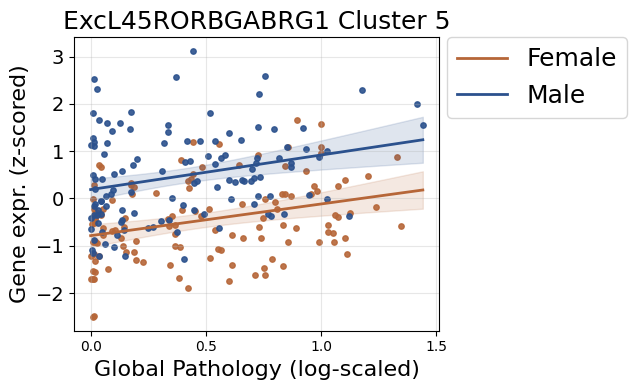

In [7]:
utils.plot_gam_sexcurves(
    cluster="Excitatory_ExcL45RORBGABRG1_Cluster_5",
    df=df,
    fitted_models=fitted_models,
    save_dir=fig_dir,
    save_prefix="GAM_sex",
    figsize=(6.5,4)
)

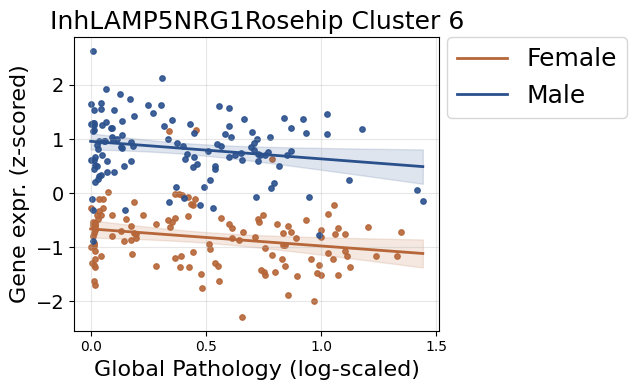

In [8]:
utils.plot_gam_sexcurves(
    cluster="Inhibitory_InhLAMP5NRG1Rosehip_Cluster_6",
    df=df,
    fitted_models=fitted_models,
    save_dir=fig_dir,
    save_prefix="GAM_sex",
    figsize=(6.5,4))


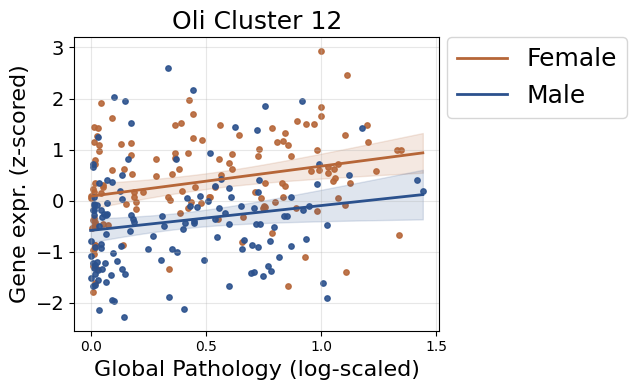

In [9]:
utils.plot_gam_sexcurves(
    cluster="Oligodendrocytes_Oli_Cluster_12",
    df=df,
    fitted_models=fitted_models,
    save_dir=fig_dir,
    save_prefix="GAM_sex",
    figsize=(6.5,4))

# GAM model w/o sex interaction

In [ ]:
N_SPL = 5 #number of splines

fitted_models = {}  # cluster - GAM object
records       = []

for cl in df.Cluster.unique():
    sub = df[df.Cluster == cl]
    X, y = sub[["gpath"]].values, sub.Expression.values

    # gridsearch chooses lambda automatically
    gam = LinearGAM(s(0, n_splines=N_SPL)).gridsearch(X, y)

    p = gam.statistics_['p_values'][0] # smooth significance
    records.append({"Cluster": cl, "p_gpath": p})

    fitted_models[cl] = gam # save for plotting

df_over = pd.DataFrame(records)
df_over["q_gpath"] = multipletests(df_over.p_gpath, method="fdr_bh")[1]

  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00
  0% (0 of 11) |                        

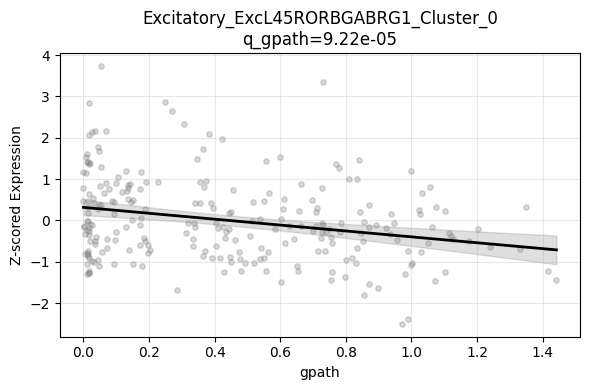

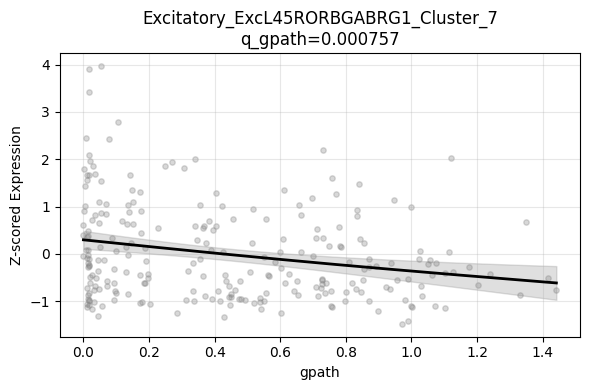

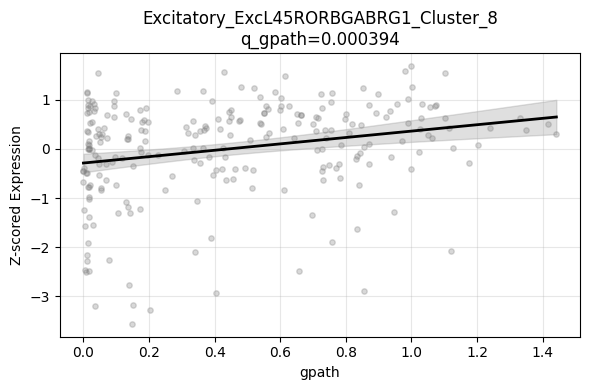

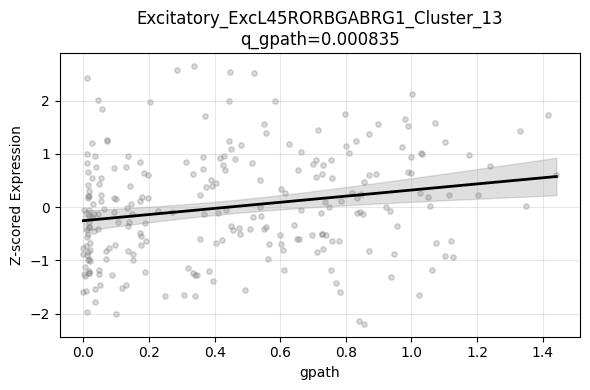

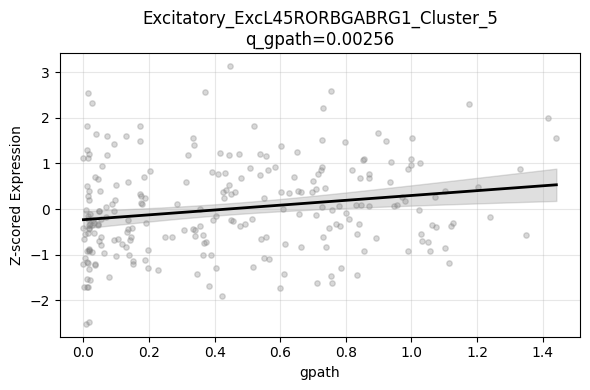

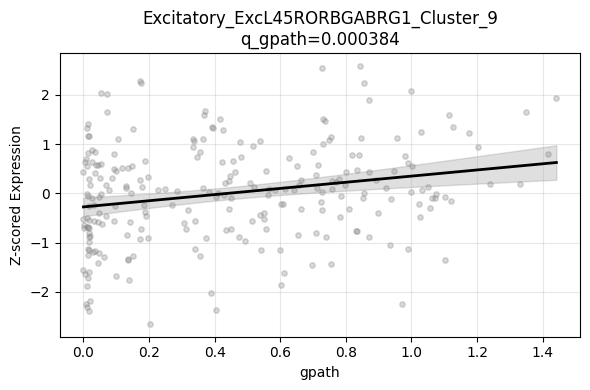

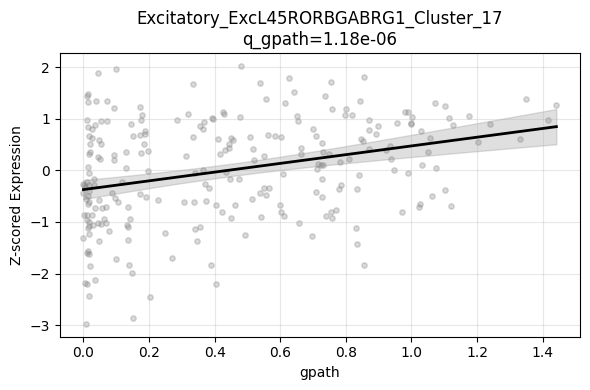

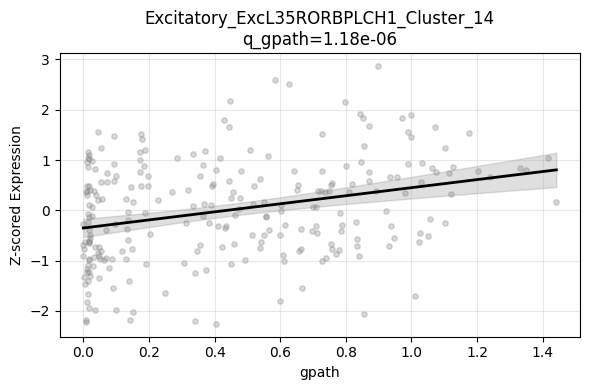

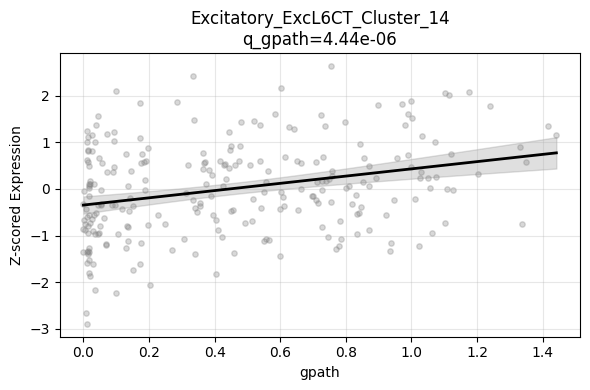

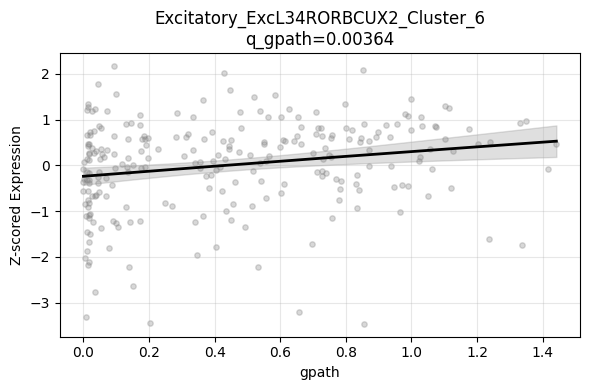

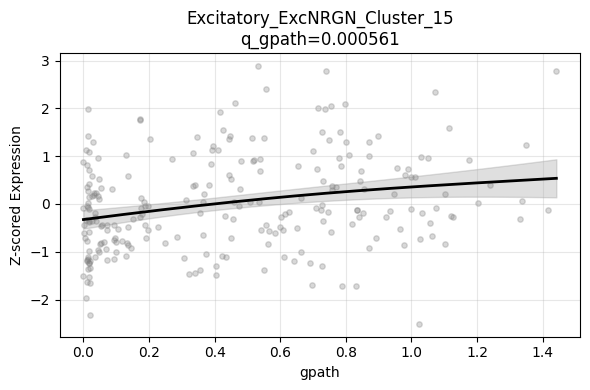

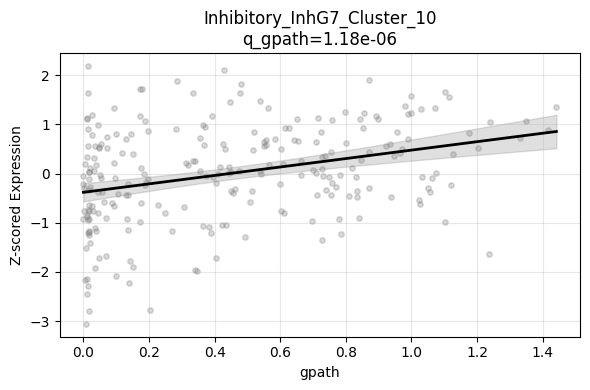

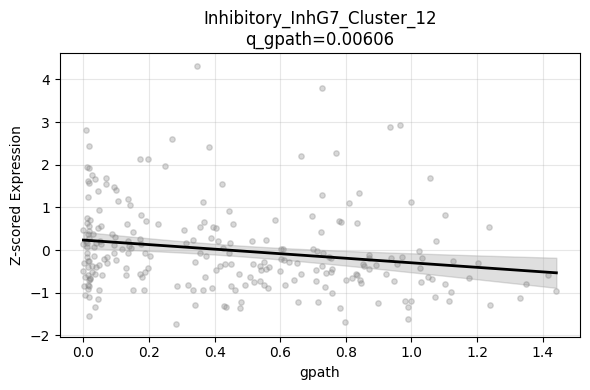

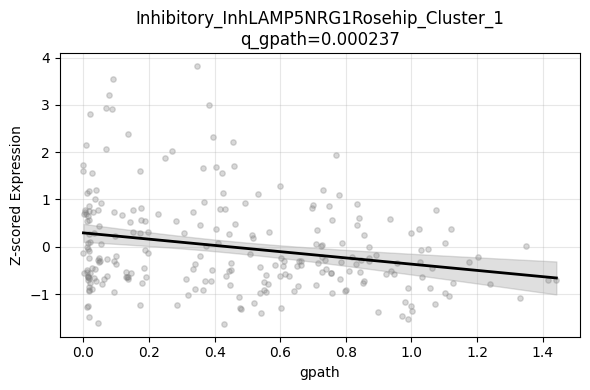

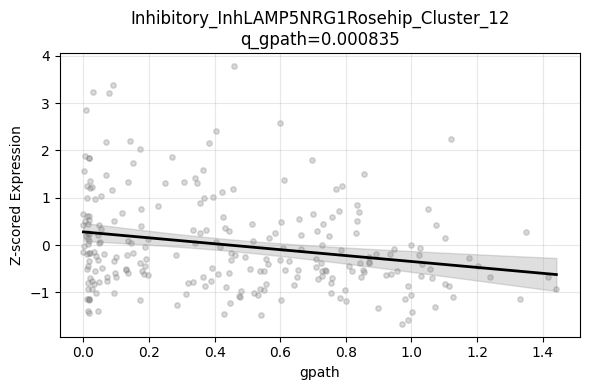

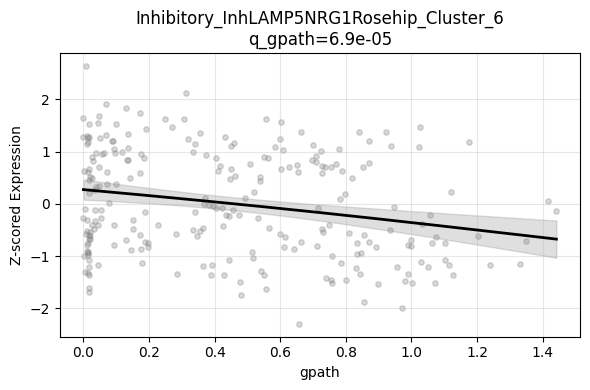

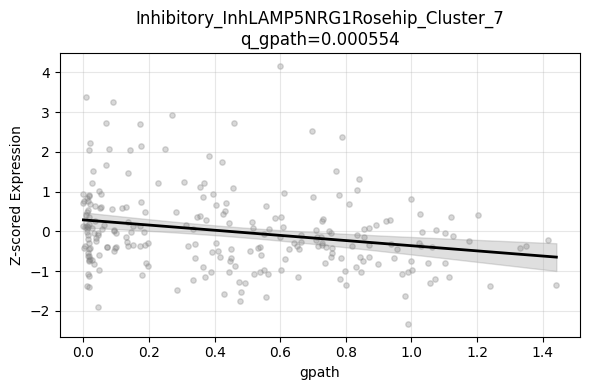

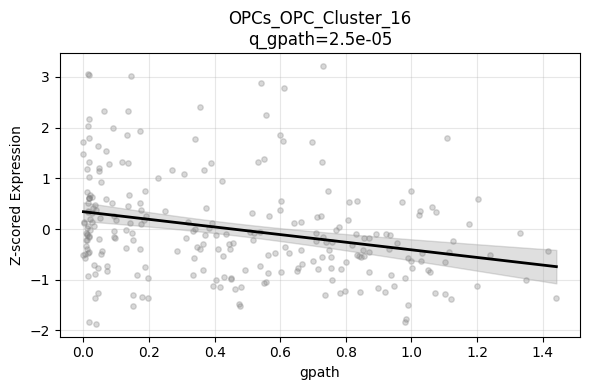

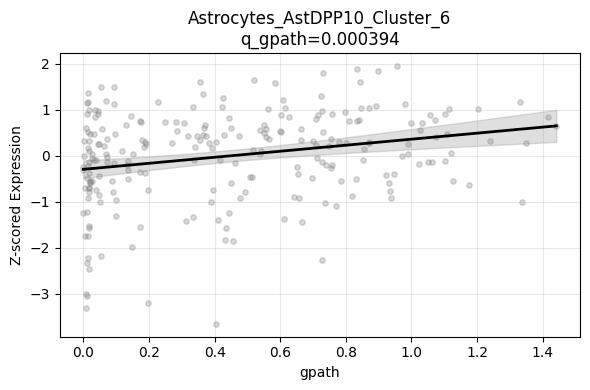

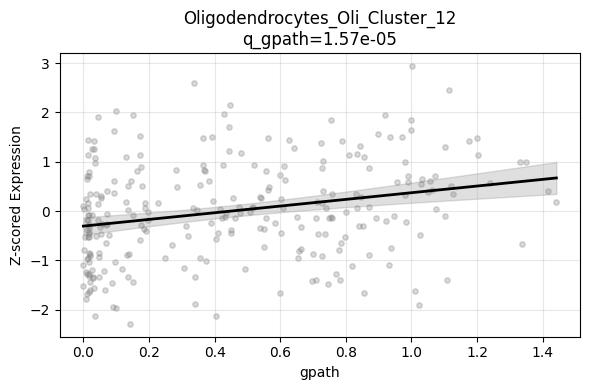

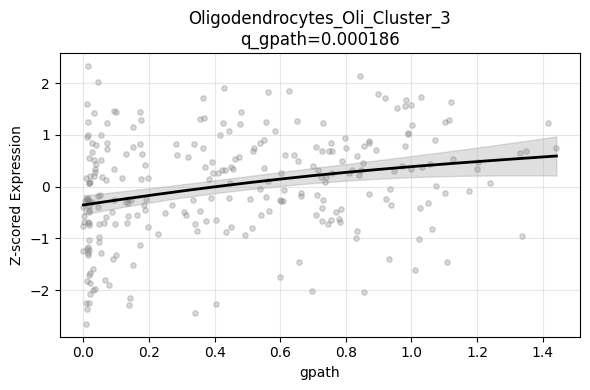

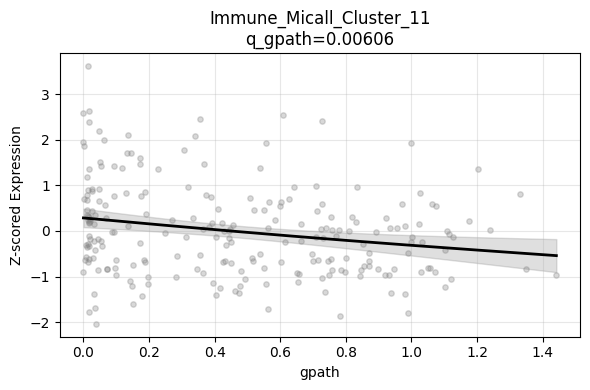

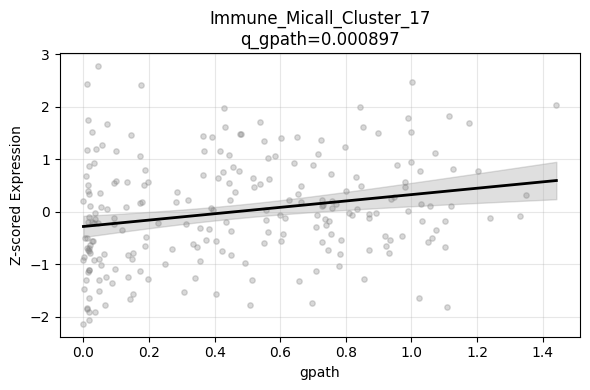

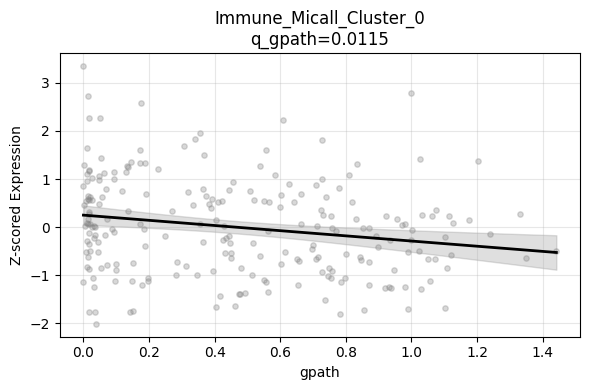

In [24]:
# Plot the no-sex GAM fit for every cluster.
# Set save_pngs = True to also save each plot as a PNG.
save_pngs = False

if save_pngs:
    png_dir = fig_dir / "GAM_overall_png"
    png_dir.mkdir(exist_ok=True)
else:
    png_dir = None   # the plot function only saves when it is given a folder

for cl in df.Cluster.unique():
    utils.plot_cluster_overall(cluster=cl, df=df, fitted_models=fitted_models, df_over=df_over, save_dir=png_dir)

## GAMs w/o sex spectral clustering

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import SpectralClustering
from scipy.stats import zscore

# Group modules by the SHAPE of their fitted GAM curve (spectral clustering).
# fitted_models here are the no-sex GAMs (gpath only).
g_grid = np.linspace(df['gpath'].min(), df['gpath'].max(), 150)

cluster_names = df.Cluster.unique()
preds = []
for cl in cluster_names:
    gam = fitted_models[cl]
    preds.append(gam.predict(g_grid))

preds = np.vstack(preds)

#row‑wise z‑score to remove offset and amplitude per module
# This makes it so the clustering happens only based on shape
preds_z = zscore(preds, axis=1, ddof=0)
preds_z = np.nan_to_num(preds_z, nan=0.0) # a perfectly flat curve would give NaN; set it to 0

# cosine + spectral clustering
W = cosine_similarity(preds_z)
W[W < 0] = 0
np.fill_diagonal(W, 1)

spec = SpectralClustering(
    n_clusters=2,
    affinity="precomputed",
    assign_labels="kmeans",
    random_state=42)
labels = spec.fit_predict(W)

gam_trend_df = pd.DataFrame({"Cluster": cluster_names, "TrendGroup": labels})
gam_trend_df.to_csv(fig_dir / 'GAM_pseudoprogression_groups.csv')

C:\Users\gabri\AppData\Roaming\Python\Python312\site-packages\sklearn\manifold\_spectral_embedding.py:285: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


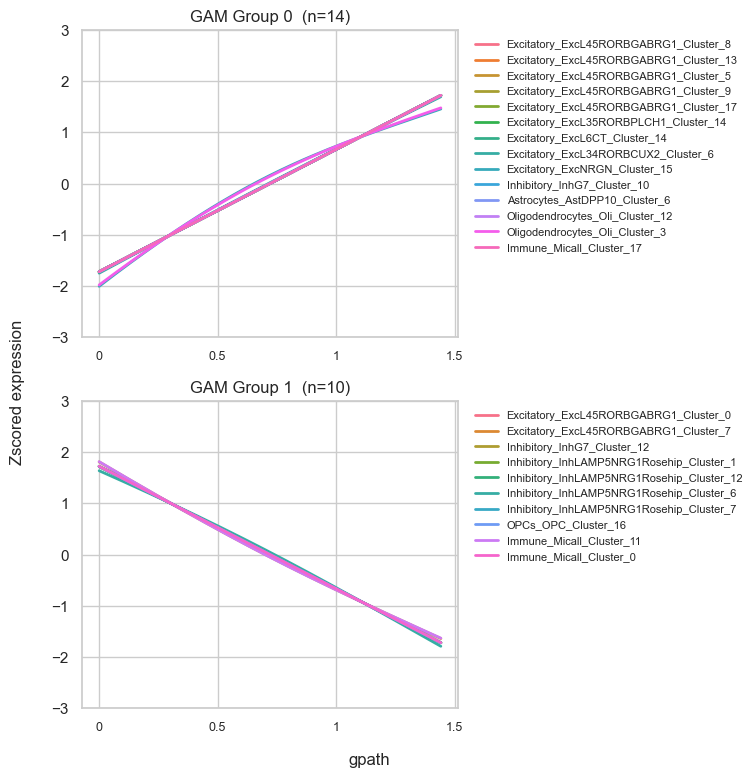

In [ ]:
# Plot every module's z-scored GAM curve, one panel per spectral group.
sns.set(style="whitegrid")

unique_groups = np.sort(gam_trend_df["TrendGroup"].unique())

# one panel per group, stacked on top of each other
n_row = len(unique_groups)
fig, axes = plt.subplots(n_row, 1, figsize=(8, 4 * n_row), sharex=True, sharey=True)

# x-axis ticks every 0.5: from the lowest gpath rounded down to the highest rounded up
lo = np.floor(g_grid.min() * 2) / 2
hi = np.ceil(g_grid.max() * 2) / 2
xticks = np.arange(lo, hi + 0.01, 0.5)
xtick_labels = [f"{t:g}" for t in xticks]

for ax, g in zip(axes, unique_groups):
    # the modules in this group; their index numbers are also their row numbers in preds_z
    members = gam_trend_df[gam_trend_df["TrendGroup"] == g].index
    palette = sns.color_palette("husl", len(members))

    for row_idx, color in zip(members, palette):
        ax.plot(g_grid, preds_z[row_idx], lw=2, color=color, label=gam_trend_df.loc[row_idx, "Cluster"])

    ax.set_title(f"GAM Group {g}  (n={len(members)})")
    ax.set_ylim(-3, 3)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xtick_labels, fontsize=9)
    ax.tick_params(axis="x", labelbottom=True)
    ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")

# axis labels shared by the whole figure
fig.text(0.5, 0.04, "gpath", ha="center", va="center", fontsize=12)
fig.text(0.06, 0.5, "Zscored expression", ha="center", va="center", rotation="vertical", fontsize=12)

plt.tight_layout(rect=[0.08, 0.05, 1, 1])
plt.savefig(fig_dir / "GAM_SPL5_preds_clusters.pdf", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

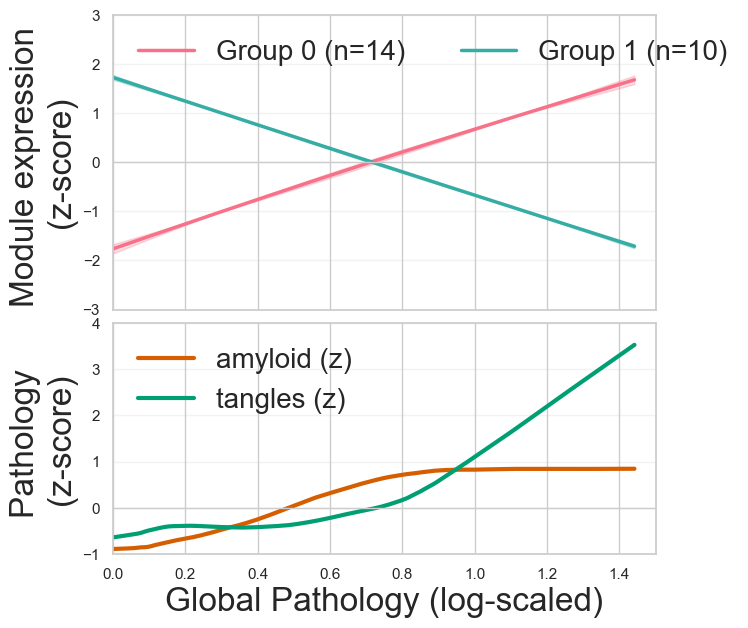

In [ ]:
# Amyloid and tangles along global pathology, for the bottom panel.
pheno_sub = pheno[["gpath", "amyloid", "tangles"]].dropna()

# z-score amyloid and tangles across people
path_sc = StandardScaler()
pheno_sub[["amyloid_z", "tangles_z"]] = path_sc.fit_transform(pheno_sub[["amyloid", "tangles"]])

# Smooth each pathology with LOWESS
path_curves = {}
for feat in ["amyloid_z", "tangles_z"]:
    sm = lowess(pheno_sub[feat], np.log1p(pheno_sub["gpath"]), frac=0.3, return_sorted=True)
    # sm: column 0 = log-gpath (sorted), column 1 = smoothed value
    path_curves[feat] = np.interp(g_grid, sm[:, 0], sm[:, 1])

# module groups on top, pathology below, sharing the x-axis
unique_groups = np.unique(labels)
palette = sns.color_palette("husl", len(unique_groups))

fig, (ax_mod, ax_path) = plt.subplots(
    nrows=2,
    sharex=True,
    figsize=(7, 7),
    gridspec_kw={"height_ratios": [7, 5.5], "hspace": 0.05},
)

# Top: mean curve per group
for lab, color in zip(unique_groups, palette):
    idx = np.where(labels == lab)[0]   # rows of preds_z that belong to this group
    curves = preds_z[idx]
    mean = curves.mean(axis=0)
    std = curves.std(axis=0, ddof=0)

    ax_mod.plot(g_grid, mean, color=color, lw=2.5, label=f"Group {lab} (n={len(idx)})")
    ax_mod.fill_between(g_grid, mean - std, mean + std, color=color, alpha=0.25)

ax_mod.set_ylabel("Module expression \n(z-score)", fontsize=24)
ax_mod.set_ylim(-3, 3)
ax_mod.axhline(0, lw=1, color="0.8")
ax_mod.legend(frameon=False, ncol=min(len(unique_groups), 3), loc="upper left", fontsize=20)
ax_mod.grid(alpha=0.25, axis="y")

# Bottom: smoothed amyloid and tangles
ax_path.plot(g_grid, path_curves["amyloid_z"], color="#D55E00", lw=3, label="amyloid (z)")
ax_path.plot(g_grid, path_curves["tangles_z"], color="#009E73", lw=3, label="tangles (z)")

ax_path.set_ylabel("Pathology \n(z-score)", fontsize=24)
ax_path.set_xlabel("Global Pathology (log-scaled)", fontsize=24)
ax_path.set_ylim(-1, 4)
ax_path.axhline(0, lw=1, color="0.8")
ax_path.legend(frameon=False, loc="upper left", fontsize=20)
ax_path.grid(alpha=0.25, axis="y")
ax_path.set_xlim(0, 1.5)

plt.savefig(fig_dir / "GAM_SPL5_preds_trends_with_pathology.pdf", dpi=300, bbox_inches="tight", transparent=True)
plt.show()